# Active Learning Pipeline — Steel Surface Inspection

This notebook walks through the full active learning pipeline step by step:

1. **Generate synthetic inspection-like images** (no real data needed to run this demo)
2. **Uncertainty scoring** — find which images the model is most unsure about
3. **Feature extraction** — encode images into an embedding space
4. **Clustering** — group similar images for diversity
5. **Candidate selection** — stratified top-K across clusters
6. **Visualisation** — t-SNE of the embedding space + uncertainty heatmap

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # add repository root to path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.manifold import TSNE
import seaborn as sns

sns.set_theme(style='whitegrid')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')

Using device: cpu


## 1. Synthetic data — simulating inspection image batches

We create 300 fake images in three categories:
- **Scratch** defects (high-frequency noise in horizontal stripes)
- **Pit** defects (Gaussian blobs)
- **Clean** surface (low-noise uniform)

This mimics the variance in the real inspection image stream.

In [ ]:
import tempfile, pathlib
from PIL import Image

TMP_DIR = pathlib.Path(tempfile.mkdtemp()) / 'steeldefect_demo'
TMP_DIR.mkdir(parents=True, exist_ok=True)

N_PER_CLASS = 100
IMG_SIZE = 64   # small for demo speed
CLASS_NAMES = ['scratch', 'pit', 'clean']

def make_scratch(rng):
    img = np.ones((IMG_SIZE, IMG_SIZE, 3), dtype=np.float32) * 0.7
    for row in rng.choice(IMG_SIZE, size=rng.integers(3, 8), replace=False):
        img[row, :] = rng.uniform(0.1, 0.4)
    img += rng.normal(0, 0.05, img.shape)
    return np.clip(img, 0, 1)

def make_pit(rng):
    img = np.ones((IMG_SIZE, IMG_SIZE, 3), dtype=np.float32) * 0.7
    for _ in range(rng.integers(2, 6)):
        cx, cy = rng.integers(10, IMG_SIZE-10, size=2)
        r = rng.integers(3, 10)
        Y, X = np.ogrid[:IMG_SIZE, :IMG_SIZE]
        mask = (X-cx)**2 + (Y-cy)**2 <= r**2
        img[mask] = rng.uniform(0.1, 0.35)
    img += rng.normal(0, 0.04, img.shape)
    return np.clip(img, 0, 1)

def make_clean(rng):
    img = np.ones((IMG_SIZE, IMG_SIZE, 3), dtype=np.float32) * rng.uniform(0.6, 0.85)
    img += rng.normal(0, 0.02, img.shape)
    return np.clip(img, 0, 1)

generators = [make_scratch, make_pit, make_clean]
rng = np.random.default_rng(42)
saved_paths = []

for cls_id, (cls_name, gen) in enumerate(zip(CLASS_NAMES, generators)):
    cls_dir = TMP_DIR / cls_name
    cls_dir.mkdir(exist_ok=True)
    for i in range(N_PER_CLASS):
        arr = (gen(rng) * 255).astype(np.uint8)
        path = cls_dir / f'{cls_name}_{i:04d}.png'
        Image.fromarray(arr).save(path)
        saved_paths.append(str(path))

print(f'Generated {len(saved_paths)} images in {TMP_DIR}')

# Preview one of each class
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, cls_name, gen in zip(axes, CLASS_NAMES, generators):
    sample = (gen(rng) * 255).astype(np.uint8)
    ax.imshow(sample)
    ax.set_title(cls_name)
    ax.axis('off')
plt.suptitle('Synthetic defect image classes', fontsize=13)
plt.tight_layout()
plt.show()

## 2. Build a simple CNN (stands in for the real ResNet/DenseNet checkpoint)

In production, replace `DummyClassifier` with `load_model(arch='resnet50', checkpoint='...')`. 

In [3]:
from steeldefect_active_learning.models.model_loader import load_model

# Use ResNet18 with random weights — same interface as production
model = load_model(arch='resnet18', checkpoint=None, num_classes=3, device=DEVICE)
print(model)

[model_loader] No checkpoint provided for 'resnet18' - using random weights.
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.

## 3. Create Dataset + DataLoader

In [4]:
from steeldefect_active_learning.data.dataset import SteelDefectDataset
from torch.utils.data import DataLoader

dataset = SteelDefectDataset(source=str(TMP_DIR), image_size=(64, 64))
loader  = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)

print(f'Dataset size: {len(dataset)} images')

# Peek at one batch
batch_tensors, batch_paths = next(iter(loader))
print(f'Batch tensor shape: {batch_tensors.shape}')
print(f'Example path: {batch_paths[0]}')

Dataset size: 300 images
Batch tensor shape: torch.Size([32, 3, 64, 64])
Example path: C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\steeldefect_demo\clean\clean_0000.png


## 4. Uncertainty Scoring

We score every image with **Shannon entropy** of the softmax output.  
Higher entropy → the model is more uncertain → better candidate for labeling.

Uncertainty — min: 0.9351  mean: 0.9675  max: 0.9910


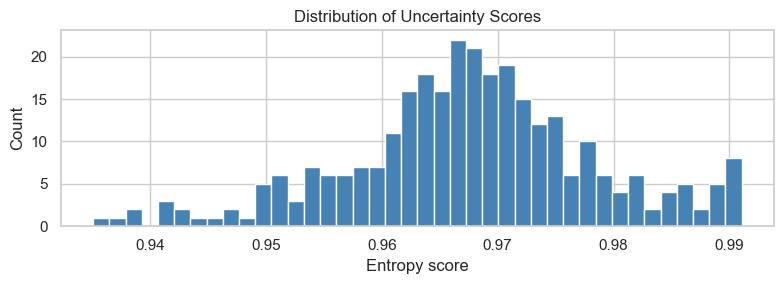

In [5]:
from steeldefect_active_learning.active_learning.uncertainty import compute_uncertainty

uncertainty_scores = compute_uncertainty(
    model=model,
    dataloader=loader,
    method='entropy',
    device=DEVICE,
    task='classification',
)

scores_arr = np.array(list(uncertainty_scores.values()))
print(f'Uncertainty — min: {scores_arr.min():.4f}  '
      f'mean: {scores_arr.mean():.4f}  '
      f'max: {scores_arr.max():.4f}')

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(scores_arr, bins=40, color='steelblue', edgecolor='white')
ax.set_xlabel('Entropy score')
ax.set_ylabel('Count')
ax.set_title('Distribution of Uncertainty Scores')
plt.tight_layout()
plt.show()

## 5. Feature Extraction

We hook into ResNet18's `avgpool` layer to get a 512-D embedding per image.
These embeddings capture *what the image looks like* to the model.

In [6]:
from steeldefect_active_learning.active_learning.feature_extractor import extract_features

embeddings = extract_features(
    model=model,
    dataloader=loader,
    layer_name='avgpool',
    device=DEVICE,
)

paths_ordered = list(embeddings.keys())
X = np.stack([embeddings[p] for p in paths_ordered])   # (N, 512)
print(f'Embeddings shape: {X.shape}')

Embeddings shape: (300, 512)


## 6. Clustering — Diversity via KMeans

Group images into 10 clusters. Each cluster represents a *type* of image.  
Selecting candidates **from each cluster** ensures we don't submit 200 nearly-identical patches.

Cluster sizes: {0: 5, 1: 101, 2: 30, 3: 23, 4: 32, 5: 41, 6: 25, 7: 24, 8: 5, 9: 14}


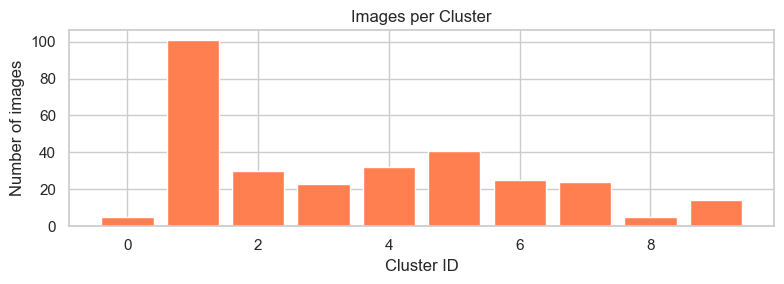

In [7]:
from steeldefect_active_learning.active_learning.clustering import cluster_embeddings, get_cluster_counts

cluster_ids = cluster_embeddings(
    embeddings=embeddings,
    n_clusters=10,
    method='kmeans',
)

counts = get_cluster_counts(cluster_ids)
print('Cluster sizes:', counts)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(list(counts.keys()), list(counts.values()), color='coral', edgecolor='white')
ax.set_xlabel('Cluster ID')
ax.set_ylabel('Number of images')
ax.set_title('Images per Cluster')
plt.tight_layout()
plt.show()

## 7. t-SNE Visualisation of the Embedding Space

Colour = cluster assignment. Point size = uncertainty score.  
Ideal: high-uncertainty points (large) spread across all clusters.

Running t-SNE (may take ~30s for 300 images)...


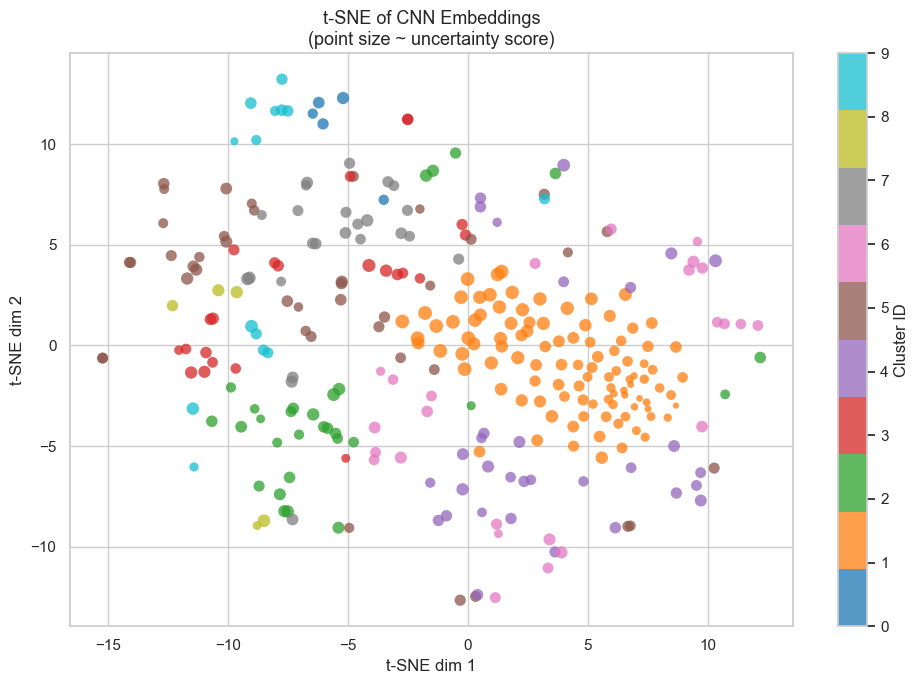

In [8]:
print('Running t-SNE (may take ~30s for 300 images)...')
tsne = TSNE(n_components=2, random_state=42, perplexity=30) #n_iter=1000)
X_2d = tsne.fit_transform(X)   # (N, 2)

cluster_arr = np.array([cluster_ids[p] for p in paths_ordered])
unc_arr     = np.array([uncertainty_scores[p] for p in paths_ordered])
unc_scaled  = (unc_arr - unc_arr.min()) / (unc_arr.max() - unc_arr.min() + 1e-8)

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=cluster_arr,
    s=20 + unc_scaled * 80,     # larger = more uncertain
    cmap='tab10',
    alpha=0.75,
    edgecolors='none',
)
plt.colorbar(scatter, ax=ax, label='Cluster ID')
ax.set_title('t-SNE of CNN Embeddings\n(point size ~ uncertainty score)', fontsize=13)
ax.set_xlabel('t-SNE dim 1')
ax.set_ylabel('t-SNE dim 2')
plt.tight_layout()
plt.show()

## 8. Candidate Selection — Stratified Top-K

Select 60 images for labeling (20% of 300), distributed equally across 10 clusters → 6 per cluster.

In [9]:
from steeldefect_active_learning.active_learning.candidate_selector import (
    select_candidates, candidates_to_dataframe
)

candidates = select_candidates(
    uncertainty_scores=uncertainty_scores,
    cluster_assignments=cluster_ids,
    labeling_budget=60,
)

cdf = candidates_to_dataframe(candidates, uncertainty_scores, cluster_ids)
print(f'Selected {len(candidates)} candidates.')
cdf.head(10)

Selected 58 candidates.


,path,uncertainty,cluster,rank_in_cluster,sensitivity_score,selection_method
0,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.975603,0,1,NaN,stratified
1,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.971166,0,2,NaN,stratified
2,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.967912,0,3,NaN,stratified
3,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.960462,0,4,NaN,stratified
4,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.960054,0,5,NaN,stratified
5,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.991046,1,1,NaN,stratified
6,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.990869,1,2,NaN,stratified
7,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.990632,1,3,NaN,stratified
8,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.990373,1,4,NaN,stratified
9,C:\Users\amrou\AppData\Local\Temp\tmpntczys3f\...,0.990365,1,5,NaN,stratified


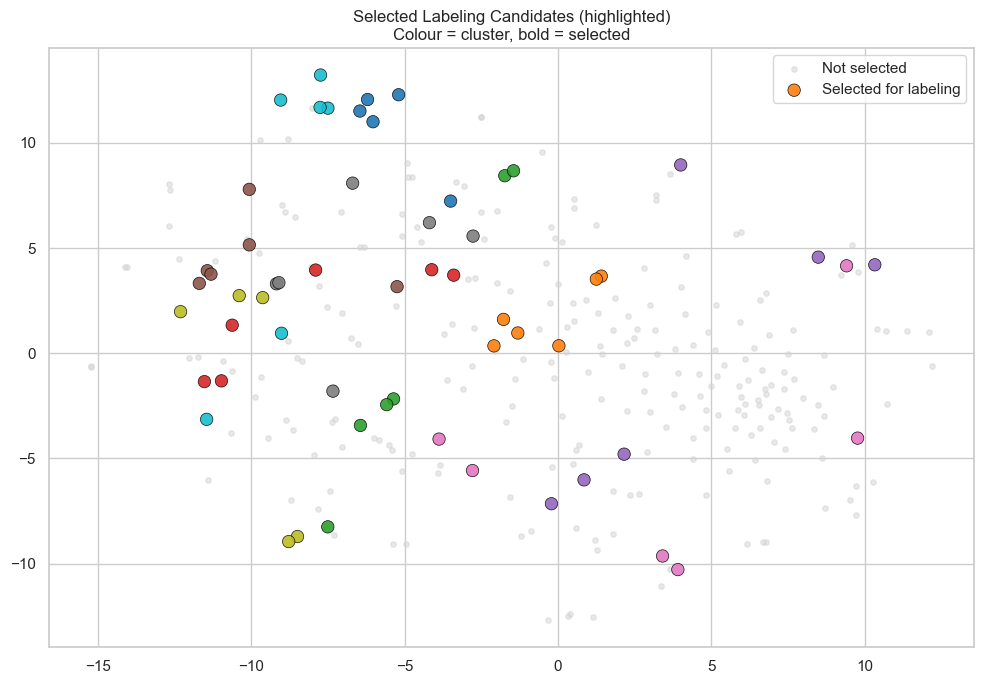

Saved to outputs/candidates_demo.csv


In [10]:
# Highlight candidates in the t-SNE plot
candidate_set = set(candidates)
is_candidate = np.array([p in candidate_set for p in paths_ordered])

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(X_2d[~is_candidate, 0], X_2d[~is_candidate, 1],
           c='lightgrey', s=15, alpha=0.5, label='Not selected')
ax.scatter(X_2d[is_candidate, 0], X_2d[is_candidate, 1],
           c=cluster_arr[is_candidate], cmap='tab10',
           s=80, alpha=0.9, edgecolors='black', linewidths=0.5,
           label='Selected for labeling')
ax.set_title('Selected Labeling Candidates (highlighted)\n'
             'Colour = cluster, bold = selected', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

# Export
os.makedirs('../outputs', exist_ok=True)
cdf.to_csv('../outputs/candidates_demo.csv', index=False)
print('Saved to outputs/candidates_demo.csv')

## 9. Per-cluster uncertainty summary

Useful for deciding where to invest more annotation budget.

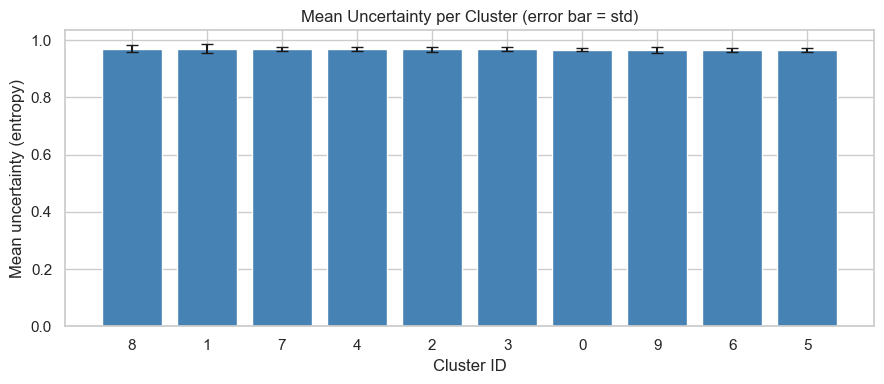

,mean,max,count
cluster,,,
8,0.970150,0.980111,5
1,0.968842,0.991046,101
7,0.968270,0.979777,24
4,0.967913,0.981057,32
2,0.967836,0.981684,30
3,0.967464,0.983040,23
0,0.967040,0.975603,5
9,0.965540,0.979827,14
6,0.965336,0.974943,25


In [11]:
import pandas as pd

summary = pd.DataFrame({
    'path': paths_ordered,
    'cluster': cluster_arr,
    'uncertainty': unc_arr,
})
cluster_summary = summary.groupby('cluster')['uncertainty'].agg(['mean', 'max', 'count'])
cluster_summary = cluster_summary.sort_values('mean', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cluster_summary.index.astype(str), cluster_summary['mean'], 
       yerr=summary.groupby('cluster')['uncertainty'].std().reindex(cluster_summary.index),
       color='steelblue', edgecolor='white', capsize=4)
ax.set_xlabel('Cluster ID')
ax.set_ylabel('Mean uncertainty (entropy)')
ax.set_title('Mean Uncertainty per Cluster (error bar = std)')
plt.tight_layout()
plt.show()

cluster_summary

## BALD vs Entropy Comparison (Houlsby et al. 2011 / Ren et al. 2021 DeepAL)

BALD separates **epistemic** uncertainty (model disagreement) from aleatoric uncertainty:

$$	ext{BALD}(x) = H[ar{p}] - \mathbb{E}_{p(w)}[H[p_w]]$$

where $ar{p} = rac{1}{T}\sum_t p^{(t)}$ is the mean over $T$ MC Dropout passes.

In [12]:
# BALD vs Entropy — synthetic comparison on random "model" outputs
# Implements BALD (Houlsby et al. 2011) reviewed in Ren et al. 2021 DeepAL Survey
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

np.random.seed(42)
n_images = 50
n_classes = 6
n_passes = 10

# Simulate MC Dropout outputs: (T, N, C) softmax probabilities
# In production: run T forward passes with model.train() (dropout active)
probs_mc = np.random.dirichlet(np.ones(n_classes), size=(n_passes, n_images))

# BALD = H(mean_p) - mean(H(p_t))
# H(mean_p): entropy of the averaged prediction (total uncertainty)
# mean(H(p_t)): average entropy per pass (aleatoric uncertainty)
# Difference = epistemic uncertainty (model disagreement)
eps = 1e-9
mean_p = probs_mc.mean(axis=0)                                          # (N, C)
H_mean = -(mean_p * np.log(mean_p + eps)).sum(axis=1)                   # (N,)
H_each = -(probs_mc * np.log(probs_mc + eps)).sum(axis=2)               # (T, N)
bald_scores = H_mean - H_each.mean(axis=0)                              # (N,) epistemic

# Standard entropy of mean prediction (normalized to [0,1])
entropy_scores = H_mean / np.log(n_classes)

# Top-20 by each method
top20_bald    = np.argsort(bald_scores)[-20:]
top20_entropy = np.argsort(entropy_scores)[-20:]
overlap = len(set(top20_bald) & set(top20_entropy))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(n_images), np.sort(bald_scores)[::-1], color="#E91E63", alpha=0.7)
axes[0].axvline(20, color="k", linestyle="--", alpha=0.5, label="Top-20 cutoff")
axes[0].set_title("BALD scores (epistemic uncertainty)\nHoulsby et al. 2011 / Ren et al. 2021")
axes[0].set_xlabel("Image rank"); axes[0].set_ylabel("BALD score"); axes[0].legend()

axes[1].bar(range(n_images), np.sort(entropy_scores)[::-1], color="#2196F3", alpha=0.7)
axes[1].axvline(20, color="k", linestyle="--", alpha=0.5, label="Top-20 cutoff")
axes[1].set_title("Normalized Entropy scores\nH / log(C) in [0,1]")
axes[1].set_xlabel("Image rank"); axes[1].set_ylabel("Normalized entropy"); axes[1].legend()

plt.suptitle(f"BALD vs Entropy — Top-20 overlap: {overlap}/20 images", fontsize=11)
plt.tight_layout()
plt.savefig("bald_vs_entropy.png", dpi=120)
print(f"BALD vs Entropy top-20 overlap: {overlap}/20")
print(f"BALD score range: [{bald_scores.min():.4f}, {bald_scores.max():.4f}]")
print(f"Entropy score range: [{entropy_scores.min():.4f}, {entropy_scores.max():.4f}]")
print("Saved: bald_vs_entropy.png")

BALD vs Entropy top-20 overlap: 8/20
BALD score range: [0.1930, 0.4517]
Entropy score range: [0.9596, 0.9977]
Saved: bald_vs_entropy.png
